# Assignment 2: Predicting Early Hospital Readmission (Diabetes Dataset)
**CS/SDP 312/314 L1, Data Science for Social Good**

**Group members:** 1. Syeda Hoorain Imran, 08704 · 2. Munib Sattar, 09239

**Language / libraries:** Python 3.13 · pandas · numpy · scikit-learn · matplotlib · joblib

**How to run:** put `diabetes_dev.csv` in the same folder as this notebook and run all cells (about 20 to 30 minutes on
a laptop with 3 parallel workers). The cleaning code is in `predict.py`, and this notebook imports it, so training and the held-out
predictions use exactly the same steps. The last section saves the final model to `model/pipeline.joblib` and the
threshold to `threshold.json`. Figures and tables for the report are saved to `figures/` and `tables/`.

**Task.** For each hospital stay, predict the probability that the patient is readmitted within 30 days
(`readmitted == "<30"`, class 1). Stays followed by a later readmission (`">30"`) or by no readmission (`"NO"`) are
class 0.

## 0. Setup and loading the data

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             precision_recall_curve)

# Our cleaning code. It lives in predict.py so that the notebook and the
# submitted prediction script can never drift apart.
import predict
from predict import clean, NUMERIC_FEATURES, CATEGORICAL_FEATURES

SEED = 42
np.random.seed(SEED)
N_JOBS = 3   # parallel workers; kept low so the notebook fits in the memory of an ordinary laptop
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
Path("figures").mkdir(exist_ok=True)   # figures used in the PDF report
Path("tables").mkdir(exist_ok=True)    # tables used in the PDF report

# diabetes_dev.csv should sit next to this notebook (the other paths are fallbacks)
candidates = [Path("diabetes_dev.csv"), Path("data") / "diabetes_dev.csv",
              Path("..") / "Package" / "diabetes_dev.csv"]
found = [p for p in candidates if p.exists()]
assert found, "Put diabetes_dev.csv in the same folder as this notebook."
raw = pd.read_csv(found[0])
print("Development data:", raw.shape[0], "stays (rows),", raw.shape[1], "columns")
print("Distinct patients:", raw["patient_nbr"].nunique())

Development data: 81281 stays (rows), 50 columns
Distinct patients: 57214


### The target

In [2]:
# Class 1 = readmitted within 30 days. ">30" and "NO" are both class 0.
y = (raw["readmitted"] == "<30").astype(int).to_numpy()

# patient_nbr is used ONLY to keep all stays of one patient on the same side of a
# split. It is never a model input (the held-out patients are new people).
groups = raw["patient_nbr"].to_numpy()

target_table = raw["readmitted"].value_counts().to_frame("Stays")
target_table["Share (%)"] = target_table["Stays"] / len(raw) * 100
target_table["Class"] = target_table.index.map({"<30": 1, ">30": 0, "NO": 0})
target_table.to_csv("tables/t01_target.csv")
print(f"Early readmissions: {y.sum():,} of {len(y):,} stays = {y.mean():.1%}")
target_table

Early readmissions: 9,053 of 81,281 stays = 11.1%


,Stays,Share (%),Class
readmitted,,,
NO,43913,54.026,0
>30,28315,34.836,0
<30,9053,11.138,1


Only about **1 stay in 9** is followed by an early readmission. This **class imbalance** matters in three places.
- **Accuracy** would be misleading. A model that says "no" for everyone is 89% accurate and useless (the Unit 10
  example of 9,990 vs 10 cases). We therefore use **average precision** (the area under the precision-recall curve),
  **ROC-AUC** and the **Brier score**, the three ranking and probability measures the held-out evaluation uses.
- The default **0.5 cut-off** would flag almost nobody, so the threshold needs its own analysis (Section 7).
- The **no-skill level** of average precision is the share of positives (0.11), not 0.5. Any model has to beat 0.11.

## 1. Exploring the raw data

### 1.1 How missing values are recorded

In [3]:
# Missing values are written as "?" in most columns. In max_glu_serum and
# A1Cresult the cell is blank (pandas reads it as NaN), which means "test not done".
missing = pd.DataFrame({
    '"?" values': (raw == "?").sum(),
    "Blank cells": raw.isna().sum(),
})
missing = missing[missing.sum(axis=1) > 0]
missing["Missing (%)"] = missing.sum(axis=1) / len(raw) * 100
missing = missing.sort_values("Missing (%)", ascending=False)
missing.to_csv("tables/t02_missing.csv")
missing

,"""?"" values",Blank cells,Missing (%)
weight,78716,0,96.844
max_glu_serum,0,77006,94.740
A1Cresult,0,67661,83.243
medical_specialty,39866,0,49.047
payer_code,32172,0,39.581
race,1860,0,2.288
diag_3,1118,0,1.375
diag_2,286,0,0.352
diag_1,17,0,0.021


In [4]:
# Does missingness itself relate to the target?
for col in ["weight", "payer_code", "medical_specialty"]:
    is_missing = raw[col] == "?"
    print(f"{col:18s} early-readmission rate: missing {y[is_missing].mean():.3f} | recorded {y[~is_missing].mean():.3f}")
for col in ["A1Cresult", "max_glu_serum"]:
    not_tested = raw[col].isna()
    print(f"{col:18s} early-readmission rate: not tested {y[not_tested].mean():.3f} | tested {y[~not_tested].mean():.3f}")

weight             early-readmission rate: missing 0.111 | recorded 0.110
payer_code         early-readmission rate: missing 0.115 | recorded 0.109
medical_specialty  early-readmission rate: missing 0.115 | recorded 0.108
A1Cresult          early-readmission rate: not tested 0.114 | tested 0.099
max_glu_serum      early-readmission rate: not tested 0.111 | tested 0.126


**What we found and what we do about it.**
- **weight** is missing for **97%** of stays, so there is almost nothing to learn from it, and whether it was recorded
  does not relate to the target (11.1% vs 11.0%). We **drop the column** (deleting a variable, Unit 03).
- **medical_specialty (49%)** and **payer_code (40%)** are missing too often to delete rows, and filling them with the
  most common value would invent a specialty for half of the patients. Their missingness is also not random: stays
  with an unknown payer or specialty are readmitted slightly more often (11.5% vs 10.9% and 10.8%). So **"Unknown"
  becomes its own category** (constant imputation), and the model can use the fact that the value is missing.
- **race (2%)** gets the same "Unknown" label, and the **diagnosis columns** (under 1.4% missing) get a "Missing" group.
- **max_glu_serum (95%)** and **A1Cresult (83%)** are blank when the test was **not done**. That is an answer, not a
  gap, so it becomes a **"Not tested"** category. Stays without an A1c test are readmitted a little more often
  (11.4% vs 9.9%). The paper that first described this dataset (Strack et al., 2014) studied exactly this link between
  A1c testing and readmission.

Deleting every row with a missing value (listwise deletion) was never an option, because weight alone is missing in
97% of rows.

### 1.2 Patients with more than one stay

In [5]:
stays_per_patient = raw["patient_nbr"].map(raw["patient_nbr"].value_counts())
band = stays_per_patient.clip(upper=5).astype(str).replace("5", "5+")
repeat = pd.DataFrame({
    "Stays (rows)": band.value_counts().sort_index(),
    "Early readmission rate (%)": pd.Series(y).groupby(band.values).mean() * 100,
})
repeat.index.name = "Stays by the same patient"
repeat.to_csv("tables/t03_repeat_patients.csv")
n_multi = (raw["patient_nbr"].value_counts() > 1).sum()
print(f"{n_multi:,} patients have more than one stay; together they account for "
      f"{(stays_per_patient > 1).sum():,} rows ({(stays_per_patient > 1).mean():.1%}).")
repeat

13,376 patients have more than one stay; together they account for 37,443 rows (46.1%).


,Stays (rows),Early readmission rate (%)
Stays by the same patient,,
1,43838,4.013
2,16692,15.067
3,7905,18.937
4,4580,21.026
5+,8266,28.055


**13,376 patients** have more than one stay, and their stays make up **46%** of all rows. Patients seen only once are
readmitted early in **4%** of stays, while patients with five or more stays are readmitted early in **28%**. This has
two consequences.
1. **Splitting.** Stays of the same person are related, so they must stay on the same side of every split (Section 3).
2. **A feature we must not build.** "Number of rows this patient has in the file" would look very predictive, but it
   is built from `patient_nbr` (not allowed) and partly from the future, because an early readmission is itself
   another row of the same patient. It would leak the answer into the input, so we do not use it.

### 1.3 Which raw variables relate to early readmission?

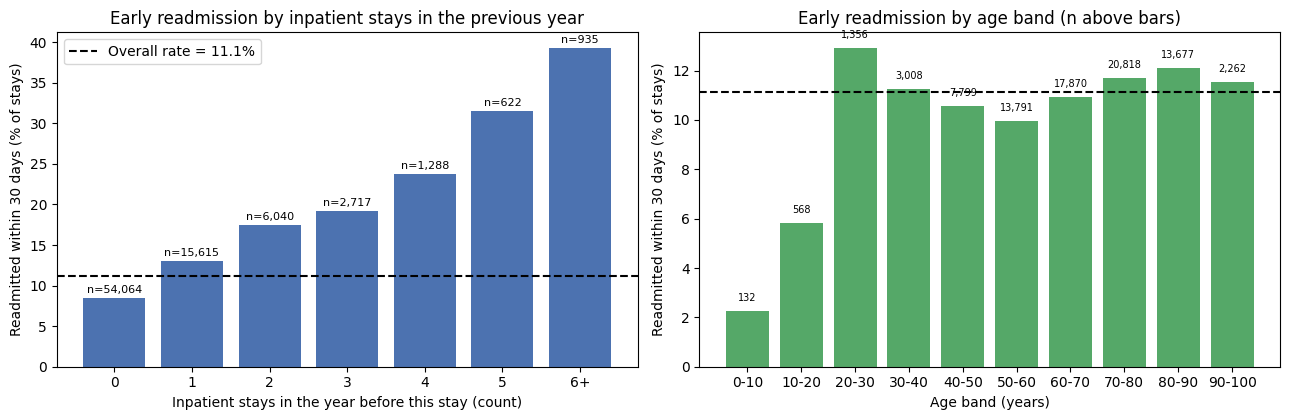

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

inpatient = raw["number_inpatient"].clip(upper=6)
rate_inp = pd.Series(y).groupby(inpatient.values).mean() * 100
n_inp = inpatient.value_counts().sort_index()
axes[0].bar([str(i) if i < 6 else "6+" for i in rate_inp.index], rate_inp.values, color="#4C72B0")
axes[0].axhline(y.mean() * 100, color="black", linestyle="--", label=f"Overall rate = {y.mean():.1%}")
for i, (r, n) in enumerate(zip(rate_inp.values, n_inp.values)):
    axes[0].text(i, r + 0.6, f"n={n:,}", ha="center", fontsize=8)
axes[0].set_title("Early readmission by inpatient stays in the previous year")
axes[0].set_xlabel("Inpatient stays in the year before this stay (count)")
axes[0].set_ylabel("Readmitted within 30 days (% of stays)")
axes[0].legend()

age_order = sorted(raw["age"].unique(), key=lambda a: int(a[1:].split("-")[0]))
rate_age = pd.Series(y).groupby(raw["age"].values).mean().reindex(age_order) * 100
n_age = raw["age"].value_counts().reindex(age_order)
axes[1].bar([a.strip("[)") for a in age_order], rate_age.values, color="#55A868")
axes[1].axhline(y.mean() * 100, color="black", linestyle="--")
for i, (r, n) in enumerate(zip(rate_age.values, n_age.values)):
    axes[1].text(i, r + 0.4, f"{n:,}", ha="center", fontsize=7)
axes[1].set_title("Early readmission by age band (n above bars)")
axes[1].set_xlabel("Age band (years)")
axes[1].set_ylabel("Readmitted within 30 days (% of stays)")
plt.tight_layout()
plt.savefig("figures/f01_rates_inpatient_age.png", dpi=200, bbox_inches="tight")
plt.show()

- **Prior inpatient stays** show the clearest pattern. The early-readmission rate climbs steadily from **8.5%** for
  patients with no inpatient stay in the previous year to **39%** for patients with six or more. Patients who are often
  in hospital tend to come back. This variable is the basis of our one-feature baseline in Section 4.
- **Age** matters much less. The rate stays between 10% and 13% in every band from 20 to 100, and only children and
  teenagers (under 20, about 700 stays) are clearly lower. Age bands are ordered, so we turn each band into a number,
  the middle of the band in years (for example "[70-80)" becomes 75).

In [7]:
# Discharge disposition: where the patient went after the stay (26 codes in IDS_mapping.csv)
disch = raw["discharge_disposition_id"]
disch_table = pd.DataFrame({"Stays": disch.value_counts(),
                            "Early readmission rate (%)": pd.Series(y).groupby(disch.values).mean() * 100})
disch_table["Our group"] = disch_table.index.map(predict.DISCHARGE_GROUP)
disch_table.index.name = "discharge_disposition_id"
disch_table.sort_values("Stays", ascending=False)

,Stays,Early readmission rate (%),Our group
discharge_disposition_id,,,
1,48178,9.255,Home
3,11058,14.831,Care facility
6,10323,12.651,Home with care
18,2971,12.083,Unknown
2,1733,16.215,Hospital transfer
22,1568,28.380,Rehab facility
11,1304,0.000,Expired
5,949,21.286,Care facility
25,769,8.583,Unknown


Discharge disposition has 26 codes, and many have only a handful of stays. Two patterns stand out.
- **Expired** stays (codes 11, 19, 20 and 21, 1,311 stays) have **no** early readmissions, since a patient who died
  cannot return. We keep these rows, because the held-out set will contain such stays as well, and the model can learn
  to give them a probability close to zero. **Hospice** stays (codes 13 and 14) are also rarely readmitted (5.6%).
- Patients sent to a **rehab unit (code 22)** or a **psychiatric hospital (code 28)** come back far more often (28% and
  36%) than patients sent home (9%).

We group the codes **by meaning**, using the descriptions in IDS_mapping.csv (last column of the table). Codes with
very few stays, such as 9, 12 or 15, join a group of similar destinations instead of standing alone, so the model does
not learn from 2 to 50 stays per code. Section 4.2 checks that this grouping costs almost nothing.

### 1.4 Diagnosis codes

In [8]:
for col in ["diag_1", "diag_2", "diag_3"]:
    print(f"{col}: {raw[col].nunique()} distinct ICD-9 codes; the 10 most common cover "
          f"{raw[col].value_counts().head(10).sum() / len(raw):.0%} of stays")

# Codes that are seen fewer than 20 times in 81,281 stays
rare = (raw["diag_1"].value_counts() < 20).sum()
print(f"diag_1 codes seen fewer than 20 times: {rare}")

diag_1: 696 distinct ICD-9 codes; the 10 most common cover 35% of stays
diag_2: 724 distinct ICD-9 codes; the 10 most common cover 42% of stays
diag_3: 760 distinct ICD-9 codes; the 10 most common cover 45% of stays
diag_1 codes seen fewer than 20 times: 406


Each diagnosis column holds about **700 different ICD-9 codes**, and **406** primary-diagnosis codes appear fewer than
20 times. One-hot encoding them directly would create about 2,000 columns, most of them too rare to learn from, and
the held-out patients will bring codes we have never seen. We therefore put every code into one of **9 disease
groups** using the standard ICD-9 chapter ranges, as in the paper that first described this dataset (Strack et al.,
2014):

| Group | ICD-9 codes |
|---|---|
| Circulatory | 390–459, 785 |
| Respiratory | 460–519, 786 |
| Digestive | 520–579, 787 |
| Diabetes | 250.xx |
| Injury | 800–999 |
| Musculoskeletal | 710–739 |
| Genitourinary | 580–629, 788 |
| Neoplasms | 140–239 |
| Other | all other codes, including V and E codes |

A missing code ("?") gets its own "Missing" group. A code we have never seen still falls into one of these ranges,
so the grouping also protects the prediction script against unseen diagnosis codes.

## 2. Cleaning and grouping the features

All cleaning steps are in the function `clean()` in `predict.py`, which this notebook imports. It works row by row, so
it gives the same result for one row or for 20,000 rows, and it never reads `readmitted`, `encounter_id` or
`patient_nbr`.

| Raw column(s) | Problem | What we do | Why |
|---|---|---|---|
| weight | 97% "?" | dropped | almost no information |
| payer_code, medical_specialty | "?" in 40% and 49% | "Unknown" category | missingness carries information, too common to delete |
| max_glu_serum, A1Cresult | blank = test not done | "Not tested" category | an answer, not a gap |
| diag_1, diag_2, diag_3 | about 700 codes each, some "?" | 9 ICD-9 disease groups plus "Missing" | too many rare codes, unseen codes still fit |
| medical_specialty | 70 specialties | 17 groups (8 large ones kept, "Surgery-…" joined, rare ones "Other") | rare specialties |
| admission_type_id, discharge_disposition_id, admission_source_id | numbers that are really categories | grouped by meaning from IDS_mapping.csv into 5, 12 and 5 groups, unknown codes become "Unknown" | the numbers have no order |
| age | text bands "[70-80)" | middle of the band in years | ordered, so we keep the order (Unit 11 maps ordinal values to numbers) |
| number_outpatient, number_emergency, number_inpatient | strongly right-skewed counts | log(1 + x), plus the log of their total | pulls in the long right tail, as in Assignment 1 |
| 23 drug columns | 21 drugs are used in under 13% of stays | keep insulin and metformin, add the number of diabetes drugs and the number of dose changes | rare columns add noise |
| change, diabetesMed | "Ch"/"No", "Yes"/"No" | 0/1 | binary |
| gender | 2 "Unknown/Invalid" | "Unknown" | |
| race | 2% "?" | **not used as a model input** | see Section 4.2 and Section 9 |

**Race.** We decided not to use race as an input. It added almost no accuracy (Section 4.2), and we did not want the
decision about who gets extra follow-up to depend on a social category. We still use race to check how well the model
works for each group (Section 9).

The steps that must be **learned from data** (median of each numeric column, scaling, which categories are common)
are not in `clean()`. They are in the fitted pipeline (Section 3), so they are learned again inside every
cross-validation fold and never see the validation rows.

In [9]:
# Apply the cleaning function from predict.py to the raw rows (without the target)
X = clean(raw.drop(columns=["readmitted"]))
print("Model input:", X.shape[0], "rows x", X.shape[1], "features")
print("Numeric features:    ", len(NUMERIC_FEATURES))
print("Categorical features:", len(CATEGORICAL_FEATURES))
print("Missing numeric values left for the imputer:", int(X[NUMERIC_FEATURES].isna().sum().sum()))
print("Missing categorical values:", int(X[CATEGORICAL_FEATURES].isna().sum().sum()))
X.head(3).T

Model input: 81281 rows x 27 features
Numeric features:     14
Categorical features: 13
Missing numeric values left for the imputer: 0
Missing categorical values: 0


,0,1,2
age_years,5,15,25
time_in_hospital,1,3,2
num_lab_procedures,41,59,11
num_procedures,0,0,5
num_medications,1,18,13
number_diagnoses,1,9,6
log_number_outpatient,0.0,0.0,1.099
log_number_emergency,0.0,0.0,0.0
log_number_inpatient,0.0,0.0,0.693
log_total_visits,0.0,0.0,1.386


In [10]:
# Early-readmission rate by the new groups (training rows only would be stricter,
# but this is description, not model fitting)
group_rates = []
for col in ["discharge_group", "diag_1_group", "admission_source", "A1Cresult"]:
    t = pd.DataFrame({"Stays": X[col].value_counts(),
                      "Rate (%)": pd.Series(y).groupby(X[col].values).mean() * 100})
    t.index = pd.MultiIndex.from_product([[col], t.index])
    group_rates.append(t)
group_rates = pd.concat(group_rates)
group_rates.to_csv("tables/t04_group_rates.csv")
group_rates

Stays  Rate (%)
discharge_group  Care facility            12741    15.313
                 Expired                   1311     0.000
                 Home                     48178     9.255
                 Home with care           10414    12.656
                 Hospice                    630     5.556
                 Hospital transfer         1757    16.505
                 Left against advice        488    13.934
                 Long-term care hospital    329     7.295
                 Outpatient referral         24     8.333
                 Psychiatric hospital       101    35.644
                 Rehab facility            1568    28.380
                 Unknown                   3740    11.364
diag_1_group     Circulatory              24301    11.555
                 Diabetes                  6997    12.520
                 Digestive                 7519    10.706
                 Genitourinary             4130    10.751
                 Injury                    5559    12.196
                 Missing                     17    23.529
                 Musculoskeletal           3962     9.465
                 Neoplasms                 2708     9.343
                 Other                    14591    11.548
                 Respiratory              11497     9.785
admission_source Emergency room           45921    11.703
                 Other                       17     5.882
                 Referral                 24624    10.409
                 Transfer                  5022     9.996
                 Unknown                   5697    10.760
A1Cresult        >7                        3044    10.250
                 >8                        6581     9.938
                 Norm                      3995     9.487
                 Not tested               67661    11.392

After grouping, every category has enough stays to learn from, and the patterns of the raw codes survive. Psychiatric
hospital (36%) and rehab facility (28%) have the highest rates, home has 9% and expired 0%. The primary
diagnosis groups differ less (9% to 13%), with diabetes and injury the highest. Stays without an A1c test have a
slightly higher rate than any tested level.

## 3. Splitting the data by patient

**Why not a random split of rows?** About 46% of the rows belong to patients with more than one stay. A random row
split would put some stays of a patient in training and other stays of the same patient in validation, and the model
could partly "recognise" the patient instead of learning patterns that carry over to new people. The instructor's
held-out set is **patient-disjoint**, so our validation must be too.

**Our design (holdout and cross-validation, Week 8 of the course).**
1. **Holdout test set.** We put 20% of the *patients* (with all their stays) aside as our own test set. It plays the
   role of the hidden held-out set and is used **once**, at the end, to check the chosen model and threshold.
2. **Grouped 5-fold cross-validation** on the other 80% of patients, for choosing models and settings. Each fold
   again keeps every patient on one side.

`StratifiedGroupKFold` does both jobs. "Group" keeps a patient's stays together; "stratified" keeps the share of early
readmissions about the same (11%) in every part, so no fold is unusually easy or hard. All imputation, scaling and
encoding is fitted inside the folds (it is part of the pipeline), so validation rows never leak into those steps.

In [11]:
# Outer split: 5 grouped, stratified parts -> the first part (20% of patients) is our holdout test set
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
g_train = groups[train_idx]

# Inner cross-validation on the training patients only
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=1)

shared = set(groups[train_idx]) & set(groups[test_idx])
split_table = pd.DataFrame({
    "Stays": [len(train_idx), len(test_idx)],
    "Patients": [len(set(groups[train_idx])), len(set(groups[test_idx]))],
    "Early readmission rate (%)": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Training (80% of patients)", "Holdout test (20% of patients)"])
split_table.to_csv("tables/t05_split.csv")
print("Patients in both training and test:", len(shared))
fold_check = [len(set(g_train[a]) & set(g_train[b])) for a, b in cv.split(X_train, y_train, g_train)]
print("Patients shared between fit and validation part, per CV fold:", fold_check)
split_table

Patients in both training and test: 0


Patients shared between fit and validation part, per CV fold: [0, 0, 0, 0, 0]


,Stays,Patients,Early readmission rate (%)
Training (80% of patients),65064,45776,11.094
Holdout test (20% of patients),16217,11438,11.315


In [12]:
def make_preprocessor(num=NUMERIC_FEATURES, cat=CATEGORICAL_FEATURES):
    """Imputation, scaling and one-hot encoding, all learned from training rows only.

    - Numeric: median imputation (resistant to the long right tails), then z-score scaling
      so that KNN distances and logistic-regression penalties treat features fairly.
    - Categorical: one-hot encoding. Levels seen fewer than 50 times in training are pooled
      into one "infrequent" column, and a level never seen in training (for example a new
      payer code in the held-out data) is sent to that same column instead of crashing.
    """
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                     min_frequency=50, sparse_output=False))])
    return ColumnTransformer([("num", numeric, num), ("cat", categorical, cat)])


n_columns = make_preprocessor().fit(X_train).transform(X_train.head()).shape[1]
print("Columns after one-hot encoding:", n_columns)

Columns after one-hot encoding: 119


## 4. Comparing models with grouped cross-validation

We compare two simple baselines with five models from the course, from the most interpretable to the most flexible:

| Model | Why it is in the comparison |
|---|---|
| No-skill baseline | Gives every stay the average rate (11%). The floor any model must beat. |
| Prior-inpatient-visits rule | One-feature rule a nurse could use without a computer: the readmission rate for each number of inpatient stays in the previous year (0, 1, ..., 6+), learned from the training folds. |
| Logistic regression | Linear, gives odds ratios that are easy to explain (Week 9). |
| Decision tree | A set of if-then rules (Units 08–09). We tune depth, leaf size and Gini vs entropy. |
| K-nearest neighbours | Predicts from the k most similar past stays (Unit 11). Needs the z-score scaling. |
| Random forest | Many deep trees on bootstrap samples, averaged (ensemble, bagging). |
| Gradient boosting | Many small trees, each fixing the errors of the previous ones (ensemble, boosting). We use scikit-learn's `HistGradientBoostingClassifier`, which bins numeric values first to run fast on 65,000 rows. |

Every model is tuned with `GridSearchCV` on the same grouped folds and is scored by **average precision** (the
primary held-out metric). ROC-AUC and the Brier score are recorded for each setting too.

In [13]:
SCORING = {"AP": "average_precision", "AUC": "roc_auc", "Brier": "neg_brier_score"}
cv_results = {}     # model name -> mean CV scores of its best setting
best_params = {}
fitted = {}         # best setting of each model, refitted on all training patients

# Baseline 1: no skill. Everyone gets the training rate, so AP equals the share of
# positives in each validation fold, AUC is 0.5 and Brier = rate x (1 - rate).
rows = []
for fit_i, val_i in cv.split(X_train, y_train, g_train):
    p = np.full(len(val_i), y_train[fit_i].mean())
    rows.append([average_precision_score(y_train[val_i], p), 0.5, brier_score_loss(y_train[val_i], p)])
cv_results["No-skill baseline"] = dict(zip(["AP", "AUC", "Brier"], np.mean(rows, axis=0)), **{"AP sd": np.std(np.array(rows)[:, 0])})

# Baseline 2: readmission rate by the number of prior inpatient stays (0..6+)
inp_train = raw["number_inpatient"].clip(upper=6).to_numpy()[train_idx]
rows = []
for fit_i, val_i in cv.split(X_train, y_train, g_train):
    rates = pd.Series(y_train[fit_i]).groupby(inp_train[fit_i]).mean()      # learned on the fit part only
    p = pd.Series(inp_train[val_i]).map(rates).fillna(y_train[fit_i].mean()).to_numpy()
    rows.append([average_precision_score(y_train[val_i], p), roc_auc_score(y_train[val_i], p),
                 brier_score_loss(y_train[val_i], p)])
cv_results["Prior-inpatient-visits rule"] = dict(zip(["AP", "AUC", "Brier"], np.mean(rows, axis=0)), **{"AP sd": np.std(np.array(rows)[:, 0])})
pd.DataFrame(cv_results).T

,AP,AUC,Brier,AP sd
No-skill baseline,0.111,0.500,0.099,0.002
Prior-inpatient-visits rule,0.164,0.602,0.096,0.010


In [14]:
model_grid = {
    "Logistic regression": (
        LogisticRegression(max_iter=3000),
        {"clf__C": [0.01, 0.1, 1.0]}),                      # C = 1 / strength of the L2 penalty
    "Decision tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"clf__criterion": ["gini", "entropy"],
         "clf__max_depth": [4, 6, 8, 10],
         "clf__min_samples_leaf": [50, 200]}),
    "K-nearest neighbours": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [50, 100, 200, 400],
         "clf__weights": ["uniform"]}),
    "Random forest": (
        RandomForestClassifier(n_estimators=300, max_features="sqrt", random_state=SEED, n_jobs=1),
        {"clf__max_depth": [10, 15, None],
         "clf__min_samples_leaf": [10, 50]}),
    "Gradient boosting": (
        HistGradientBoostingClassifier(random_state=SEED, early_stopping=False),
        {"clf__learning_rate": [0.05, 0.1],
         "clf__max_iter": [100, 200],                        # number of trees
         "clf__max_leaf_nodes": [15, 31],
         "clf__min_samples_leaf": [50, 200]}),
}

grid_tables = {}
for name, (estimator, grid) in model_grid.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", estimator)])
    search = GridSearchCV(pipe, grid, scoring=SCORING, refit="AP", cv=cv, n_jobs=N_JOBS)
    search.fit(X_train, y_train, groups=g_train)
    res, b = search.cv_results_, search.best_index_
    cv_results[name] = {"AP": res["mean_test_AP"][b], "AUC": res["mean_test_AUC"][b],
                        "Brier": -res["mean_test_Brier"][b], "AP sd": res["std_test_AP"][b]}
    best_params[name] = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    fitted[name] = search.best_estimator_
    grid_tables[name] = (pd.DataFrame(res["params"]).rename(columns=lambda c: c.replace("clf__", ""))
                         .assign(AP=res["mean_test_AP"], AUC=res["mean_test_AUC"], Brier=-res["mean_test_Brier"])
                         .sort_values("AP", ascending=False))
    print(f"{name:22s} best {best_params[name]}  CV AP = {cv_results[name]['AP']:.4f}")

Logistic regression    best {'C': 1.0}  CV AP = 0.2059


Decision tree          best {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 50}  CV AP = 0.2009


K-nearest neighbours   best {'n_neighbors': 400, 'weights': 'uniform'}  CV AP = 0.1866


Random forest          best {'max_depth': 15, 'min_samples_leaf': 10}  CV AP = 0.2197


Gradient boosting      best {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}  CV AP = 0.2282


In [15]:
comparison = pd.DataFrame(cv_results).T[["AP", "AP sd", "AUC", "Brier"]]
comparison.index.name = "Model (grouped 5-fold CV on training patients)"
comparison["Best setting"] = [best_params.get(m, "") for m in comparison.index]
comparison.to_csv("tables/t06_model_comparison.csv")
comparison

,AP,AP sd,AUC,Brier,Best setting
Model (grouped 5-fold CV on training patients),,,,,
No-skill baseline,0.111,0.002,0.500,0.099,
Prior-inpatient-visits rule,0.164,0.010,0.602,0.096,
Logistic regression,0.206,0.010,0.667,0.095,{'C': 1.0}
Decision tree,0.201,0.007,0.655,0.095,"{'criterion': 'entropy', 'max_depth': 8, 'min_..."
K-nearest neighbours,0.187,0.007,0.641,0.096,"{'n_neighbors': 400, 'weights': 'uniform'}"
Random forest,0.220,0.008,0.675,0.094,"{'max_depth': 15, 'min_samples_leaf': 10}"
Gradient boosting,0.228,0.006,0.679,0.094,"{'learning_rate': 0.05, 'max_iter': 100, 'max_..."


In [16]:
# The six best settings of the decision tree and of gradient boosting (all settings are in grid_tables)
display(grid_tables["Decision tree"].head(6).round(4))
grid_tables["Gradient boosting"].head(6).round(4)

,criterion,max_depth,min_samples_leaf,AP,AUC,Brier
12,entropy,8,50,0.201,0.655,0.095
4,gini,8,50,0.200,0.656,0.095
13,entropy,8,200,0.200,0.655,0.095
15,entropy,10,200,0.200,0.650,0.095
6,gini,10,50,0.199,0.651,0.096
14,entropy,10,50,0.198,0.646,0.096


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,AP,AUC,Brier
2,0.05,100,31,50,0.228,0.679,0.094
4,0.05,200,15,50,0.228,0.679,0.094
8,0.10,100,15,50,0.227,0.679,0.094
0,0.05,100,15,50,0.227,0.678,0.094
10,0.10,100,31,50,0.227,0.678,0.094
6,0.05,200,31,50,0.227,0.677,0.094


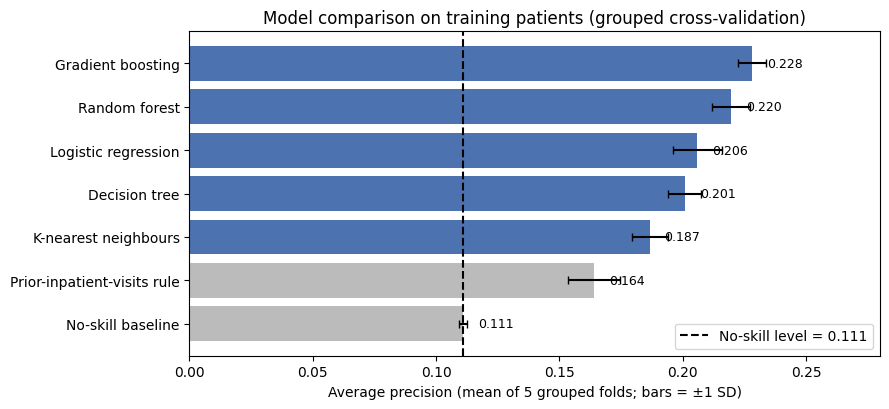

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.2))
order = comparison.sort_values("AP").index
ax.barh(order, comparison.loc[order, "AP"], xerr=comparison.loc[order, "AP sd"],
        color=["#BBBBBB" if "baseline" in m or "rule" in m else "#4C72B0" for m in order], capsize=3)
ax.axvline(y_train.mean(), color="black", linestyle="--", label=f"No-skill level = {y_train.mean():.3f}")
for i, m in enumerate(order):
    ax.text(comparison.loc[m, "AP"] + 0.006, i, f"{comparison.loc[m, 'AP']:.3f}", va="center", fontsize=9)
ax.set_xlabel("Average precision (mean of 5 grouped folds; bars = ±1 SD)")
ax.set_title("Model comparison on training patients (grouped cross-validation)")
ax.set_xlim(0, 0.28)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/f02_model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**Results.**
- Every model beats both baselines. The **one-feature rule** (prior inpatient stays) already lifts AP from
  0.111 to **0.164**, which shows how much of the
  signal sits in that single variable.
- **Logistic regression (0.206)**, the **decision tree (0.201)** and **KNN (0.187)** are close to
  each other. KNN is the weakest. Its best k was 400, the largest we tried, so it works best when it averages over a big
  neighbourhood, close to a smoothed average rate. With 119 columns, most of them 0/1 and all weighted
  equally, the distance between two stays is not very informative (Unit 11 notes that KNN treats every feature as equally
  important unless we weight them).
- For the **decision tree**, Gini and entropy give almost the same result at depth 8, and depth 8 beat both shallower
  trees (under-fitting) and deeper trees (over-fitting).
- The two **ensembles** are best. **Gradient boosting (0.228, AUC 0.679)** is ahead of the random forest
  (0.220) and has a small spread across folds (±0.006). Many boosting settings score within 0.003 of each
  other, so the exact setting matters little.
- All AUCs are between 0.64 and 0.68. This is modest but typical for readmission prediction from administrative records,
  because much of what causes a return (support at home, whether medicines are taken) is not in the data.

### 4.1 Does the grouped split matter here? A leakage check

In [18]:
# Same models, same training rows, two ways of splitting: by patient (honest) and by row (leaky)
leak_rows = []
row_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
leak_models = {
    "Fully grown decision tree": DecisionTreeClassifier(random_state=SEED),
    "1-nearest neighbour": KNeighborsClassifier(n_neighbors=1),
    "Gradient boosting (chosen setting)": clone(fitted["Gradient boosting"].named_steps["clf"]),
}
for name, est in leak_models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", est)])
    for split_name, splitter, grp in [("Grouped by patient", cv, g_train), ("Random rows (leaky)", row_cv, None)]:
        r = cross_validate(pipe, X_train, y_train, groups=grp, cv=splitter, n_jobs=N_JOBS,
                           scoring={"AP": "average_precision", "AUC": "roc_auc"})
        leak_rows.append([name, split_name, r["test_AP"].mean(), r["test_AUC"].mean()])
leak = pd.DataFrame(leak_rows, columns=["Model", "Split", "AP", "AUC"]).pivot(index="Model", columns="Split")
leak.to_csv("tables/t07_leakage_check.csv")
leak

AP                                    AUC                    
Split                              Grouped by patient Random rows (leaky) Grouped by patient Random rows (leaky)
Model                                                                                                           
1-nearest neighbour                             0.116               0.118              0.520               0.527
Fully grown decision tree                       0.119               0.120              0.529               0.533
Gradient boosting (chosen setting)              0.228               0.229              0.679               0.679

**What we expected.** The random-row split should look better, because a model could partly recognise returning patients.

**What we found.** The difference is tiny, at most 0.002 in AP, which is smaller than the spread between folds.
This holds even for the 1-nearest-neighbour model, which simply copies the label of the most similar training stay. A
patient's stays look quite different from each other (different diagnoses, lengths of stay, lab counts), and we use no
patient-level feature, so nothing in the inputs reliably identifies a person.

So with our features, grouping by patient matters less than we expected. We still use it because it is the only design
that matches how the model will be used (on new patients) and how it is evaluated (on a patient-disjoint held-out set).
The real leakage danger was the patient-level feature from Section 1.2, which we did not build.

### 4.2 Checking our cleaning and grouping choices

Each line below changes **one** cleaning choice and scores the chosen gradient-boosting setting on the same grouped
folds. If a simpler or more detailed version had done clearly better, we would have changed our cleaning.

In [19]:
gb_setting = clone(fitted["Gradient boosting"].named_steps["clf"])   # chosen setting, unfitted
train_raw = raw.iloc[train_idx]

def variant_score(X_variant, num, cat):
    pipe = Pipeline([("prep", make_preprocessor(num, cat)), ("clf", clone(gb_setting))])
    r = cross_validate(pipe, X_variant, y_train, groups=g_train, cv=cv, n_jobs=N_JOBS,
                       scoring={"AP": "average_precision", "AUC": "roc_auc"})
    return r["test_AP"].mean(), r["test_AUC"].mean()

variants = {"Our cleaned features": (X_train, NUMERIC_FEATURES, CATEGORICAL_FEATURES)}

v = X_train.assign(race=train_raw["race"].replace("?", "Unknown").to_numpy())
variants["Race added as an input"] = (v, NUMERIC_FEATURES, CATEGORICAL_FEATURES + ["race"])

v = X_train.assign(discharge_group=train_raw["discharge_disposition_id"].astype(str).to_numpy())
variants["Raw 26 discharge codes instead of 12 groups"] = (v, NUMERIC_FEATURES, CATEGORICAL_FEATURES)

v = X_train.copy()
for col in ["diag_1", "diag_2", "diag_3"]:          # "250.83" -> "250", rare codes pooled by the encoder
    v[col + "_group"] = train_raw[col].astype(str).str.split(".").str[0].to_numpy()
variants["3-digit diagnosis codes instead of 9 groups"] = (v, NUMERIC_FEATURES, CATEGORICAL_FEATURES)

variants["payer_code left out"] = (X_train, NUMERIC_FEATURES,
                                   [c for c in CATEGORICAL_FEATURES if c != "payer_code"])

choice_rows = {name: variant_score(*args) for name, args in variants.items()}
choices = pd.DataFrame(choice_rows, index=["CV AP", "CV AUC"]).T
choices["AP change"] = choices["CV AP"] - choices.loc["Our cleaned features", "CV AP"]
choices.to_csv("tables/t08_cleaning_choices.csv")
choices.round(4)

,CV AP,CV AUC,AP change
Our cleaned features,0.228,0.679,0.000e+00
Race added as an input,0.229,0.679,5.000e-04
Raw 26 discharge codes instead of 12 groups,0.228,0.679,2.000e-04
3-digit diagnosis codes instead of 9 groups,0.225,0.676,-3.100e-03
payer_code left out,0.227,0.677,-1.700e-03


- **Race as an input** changes AP by only +0.0005, less than the spread between folds,
  so leaving it out costs nothing measurable (see also Section 9).
- **All 26 raw discharge codes** score 0.228 against 0.228 for our
  12 groups, so grouping by meaning loses almost nothing and avoids codes with only a handful of stays.
- **3-digit diagnosis codes** (0.225) do slightly worse than the 9
  disease groups. More detail adds rare levels faster than it adds information.
- **Leaving out payer_code** lowers AP to 0.226, so the payer (including "Unknown") carries a
  little information and we keep it.

An earlier version of our grouping put rehab facilities (code 22, 28% readmitted) together with long-term care hospitals
(code 23, 7%). This check showed the raw codes doing better, which led us to separate the two destinations.

### 4.3 What the models learned

In [20]:
# Logistic regression: odds ratios. Numeric features are z-scored, so their odds ratio is
# "per one standard deviation"; for a one-hot column it compares that level with the rest.
lr = fitted["Logistic regression"]
names = [n.split("__", 1)[1] for n in lr.named_steps["prep"].get_feature_names_out()]
odds = pd.Series(np.exp(lr.named_steps["clf"].coef_[0]), index=names).sort_values()
odds_table = pd.concat([odds.tail(8)[::-1], odds.head(6)]).to_frame("Odds ratio")
odds_table.to_csv("tables/t09_lr_odds_ratios.csv")
odds_table

,Odds ratio
discharge_group_Psychiatric hospital,4.878
discharge_group_Rehab facility,3.906
discharge_group_Hospital transfer,1.766
specialty_Oncology/Hematology,1.625
discharge_group_Care facility,1.614
discharge_group_Left against advice,1.391
log_number_inpatient,1.343
diag_2_group_Neoplasms,1.281
discharge_group_Expired,0.029
discharge_group_Hospice,0.410


In [21]:
# Gradient boosting: permutation importance on the holdout patients. Each cleaned feature is
# shuffled in turn, and we measure how much average precision drops. A big drop = the model
# relies on that feature. (This uses the 28 cleaned features, before one-hot encoding.)
gb = fitted["Gradient boosting"]
perm = permutation_importance(gb, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=SEED, n_jobs=N_JOBS)
importance = (pd.DataFrame({"Drop in AP (mean)": perm.importances_mean, "SD": perm.importances_std},
                           index=X_test.columns).sort_values("Drop in AP (mean)", ascending=False))
importance.to_csv("tables/t10_permutation_importance.csv")
importance.head(10)

,Drop in AP (mean),SD
discharge_group,0.061,2.611e-03
log_number_inpatient,0.058,1.749e-03
log_total_visits,0.010,1.018e-03
diag_1_group,0.009,1.569e-03
payer_code,0.008,1.281e-03
specialty,0.007,8.216e-04
number_diagnoses,0.005,1.272e-03
admission_type,0.004,9.616e-04
log_number_emergency,0.002,3.085e-04
admission_source,0.002,5.332e-04


Both models point to the same drivers.
- For **gradient boosting**, the **discharge destination** and the number of **prior inpatient stays** are by far the most
  important features. Shuffling either one lowers holdout AP by about 0.06, about a quarter of
  the model's AP. Next come the total number of prior visits, the primary diagnosis group and the payer code, each with
  an effect about six times smaller.
- In **logistic regression**, discharge to a **psychiatric hospital** (odds ratio 4.9),
  a **rehab facility** (3.9) or **another hospital**
  (1.8) raises the odds of early readmission, and so does each extra standard
  deviation of (log) prior inpatient stays (1.34). Stays that ended in **death**
  (0.03) or **hospice** (0.41) have much lower odds, as expected.

Medication and lab-test features add little once these are known.

## 5. Choosing the final model

We choose **gradient boosting**.
- It has the best average precision, the primary held-out metric (0.228 in cross-validation), together with the
  best AUC and Brier score, and a small spread across folds.
- It finds interactions on its own (for example, prior visits may matter more for some discharge destinations), which a
  linear model can only do with hand-made terms.
- **What we give up** is a readable formula. Logistic regression is 0.022 lower in AP (about
  10% worse), but each coefficient is an odds ratio. We keep it as our
  **interpretable reference**, and we explain the boosting model with permutation importance (Section 4.3) and the
  subgroup checks (Section 9).
- The random forest is close (0.220) but slightly worse on every measure, and its saved file would be much larger.

The chosen setting is a learning rate of 0.05, 100 trees, at most 31
leaves per tree and at least 50 stays per leaf. scikit-learn switches on early stopping by default for data
this size, which holds out a random 10% of rows that is **not** grouped by patient. We turned it off and tuned the number
of trees on our own grouped folds instead, which also makes the model fully repeatable.

In [22]:
FINAL_MODEL = "Gradient boosting"
final_settings = best_params[FINAL_MODEL]
print("Final model:", FINAL_MODEL, final_settings)

Final model: Gradient boosting {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31, 'min_samples_leaf': 50}


## 6. Probability quality (calibration)

In [23]:
# Out-of-fold predictions on the training patients: each stay is predicted by a model
# that never saw that patient. These are used for calibration and for the threshold.
oof = {}
for name in ["Logistic regression", "Gradient boosting"]:
    oof[name] = cross_val_predict(clone(fitted[name]), X_train, y_train, groups=g_train, cv=cv,
                                  method="predict_proba", n_jobs=N_JOBS)[:, 1]
    print(f"{name:20s} out-of-fold AP {average_precision_score(y_train, oof[name]):.4f} | "
          f"AUC {roc_auc_score(y_train, oof[name]):.4f} | Brier {brier_score_loss(y_train, oof[name]):.4f}")

# Reliability table: put stays into 10 equal-size groups by predicted probability and
# compare the average prediction with the share that was really readmitted.
p = oof[FINAL_MODEL]
decile = pd.qcut(p, 10, labels=False, duplicates="drop")
calib = pd.DataFrame({"Mean predicted (%)": pd.Series(p).groupby(decile).mean() * 100,
                      "Observed rate (%)": pd.Series(y_train).groupby(decile).mean() * 100,
                      "Stays": pd.Series(p).groupby(decile).size()})
calib.index = [f"Group {i + 1}" for i in calib.index]
calib.to_csv("tables/t11_calibration.csv")
calib

Logistic regression  out-of-fold AP 0.2045 | AUC 0.6666 | Brier 0.0948


Gradient boosting    out-of-fold AP 0.2272 | AUC 0.6786 | Brier 0.0936


,Mean predicted (%),Observed rate (%),Stays
Group 1,3.653,3.304,6507
Group 2,5.687,5.487,6506
Group 3,6.673,6.532,6506
Group 4,7.616,7.392,6507
Group 5,8.710,8.469,6506
Group 6,10.052,9.822,6506
Group 7,11.670,11.941,6507
Group 8,13.665,14.264,6506
Group 9,16.874,16.769,6506
Group 10,25.992,26.956,6507


In [24]:
# The same check with class weights: "balanced" weights are a common fix for imbalance,
# so we test what they do to the probabilities.
lr_bal = clone(fitted["Logistic regression"]).set_params(clf__class_weight="balanced")
p_bal = cross_val_predict(lr_bal, X_train, y_train, groups=g_train, cv=cv, method="predict_proba", n_jobs=N_JOBS)[:, 1]
print(f"Logistic regression, balanced weights: AP {average_precision_score(y_train, p_bal):.4f} | "
      f"AUC {roc_auc_score(y_train, p_bal):.4f} | Brier {brier_score_loss(y_train, p_bal):.4f} | "
      f"mean predicted {p_bal.mean():.3f} vs real rate {y_train.mean():.3f}")

Logistic regression, balanced weights: AP 0.2030 | AUC 0.6675 | Brier 0.2263 | mean predicted 0.462 vs real rate 0.111


**Calibration.** For gradient boosting, the average predicted probability in each of the 10 groups is within
1.0 percentage points of the share that was really readmitted (for example 26.0%
predicted vs 27.0% observed in the highest-risk group). The probabilities can therefore be read
as real risks. This matters because the held-out evaluation includes the Brier score, and because the threshold of
0.12 then really means "about a 12% chance".

**Why we did not use class weights.** Re-weighting the rare class is a common fix for imbalance. It barely changes the
ranking (AP 0.203 vs 0.204, AUC 0.667 vs 0.667), but it pushes every
probability up. The average prediction becomes 46% when the real rate is 11%, and the Brier
score more than doubles (0.226 vs 0.095). We handle the imbalance with the **threshold**
(Section 7) instead and keep honest probabilities.

## 7. Choosing the decision threshold

A threshold turns a probability into a yes/no decision. Stays with a probability at or above the threshold are
flagged for extra follow-up. The two kinds of error do not cost the same.
- **Missing a patient who comes back (false negative).** The patient has another hospital stay, with the health risk
  and cost of a new admission.
- **An unneeded follow-up (false positive).** A nurse's phone call, a medication check or an earlier clinic appointment
  for someone who would have been fine. This uses staff time but does little harm.

We use the cost-sensitive view of errors from Unit 10. Each error gets a cost, and we pick the threshold with the
**lowest total cost** on the **out-of-fold predictions of the training patients** (the holdout patients are not used).
As a team we judged that **missing a readmission is about 7 times as costly as an unneeded follow-up**. A follow-up is
cheap, but it does not prevent every readmission, so the ratio should not be extreme. Because the ratio is a
judgement, we also show 3, 5 and 10.

In [25]:
COST_MISS = 7            # cost of missing a patient who is readmitted (false negative)
COST_ALARM = 1           # cost of an unneeded follow-up (false positive)

def threshold_table(y_true, prob, thresholds):
    rows = []
    for t in thresholds:
        pred = (prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        rows.append({"Threshold": t, "Flagged (%)": pred.mean() * 100,
                     "Precision": tp / max(tp + fp, 1), "Recall": tp / (tp + fn),
                     "F1": f1_score(y_true, pred, zero_division=0),
                     "False alarm rate": fp / (fp + tn),
                     "Cost per 100 stays": (COST_MISS * fn + COST_ALARM * fp) / len(y_true) * 100})
    return pd.DataFrame(rows)

grid_t = np.round(np.arange(0.05, 0.51, 0.01), 2)
thr = threshold_table(y_train, oof[FINAL_MODEL], grid_t)
best_cost = thr.loc[thr["Cost per 100 stays"].idxmin()]
best_f1 = thr.loc[thr["F1"].idxmax()]
THRESHOLD = float(best_cost["Threshold"])
print(f"Lowest cost (miss = {COST_MISS} x alarm): threshold {THRESHOLD:.2f}")
print(f"Highest F1: threshold {best_f1['Threshold']:.2f}")
show_t = [0.05, 0.08, 0.10, 0.12, 0.14, 0.16, 0.18, 0.20, 0.25, 0.30, 0.40, 0.50, THRESHOLD]
shown = thr[np.isclose(thr["Threshold"].to_numpy()[:, None], show_t).any(axis=1)]
shown.to_csv("tables/t12_thresholds.csv", index=False)
shown

Lowest cost (miss = 7 x alarm): threshold 0.12
Highest F1: threshold 0.13


,Threshold,Flagged (%),Precision,Recall,F1,False alarm rate,Cost per 100 stays
0,0.05,90.766,0.119,0.974,0.212,8.994e-01,82.008
3,0.08,61.141,0.146,0.804,0.247,5.874e-01,67.483
5,0.10,45.277,0.166,0.677,0.266,4.248e-01,62.881
7,0.12,33.110,0.188,0.560,0.281,3.025e-01,61.068
9,0.14,23.346,0.209,0.439,0.283,2.078e-01,62.037
11,0.16,16.985,0.231,0.353,0.279,1.470e-01,63.299
13,0.18,12.246,0.256,0.282,0.268,1.025e-01,64.868
15,0.20,8.641,0.282,0.220,0.247,6.974e-02,66.771
20,0.25,3.939,0.342,0.121,0.179,2.916e-02,70.824
25,0.30,2.113,0.407,0.078,0.130,1.409e-02,72.884


Miss = 3 x alarm: lowest cost at threshold 0.27
Miss = 5 x alarm: lowest cost at threshold 0.17
Miss = 7 x alarm: lowest cost at threshold 0.12


Miss = 10 x alarm: lowest cost at threshold 0.09


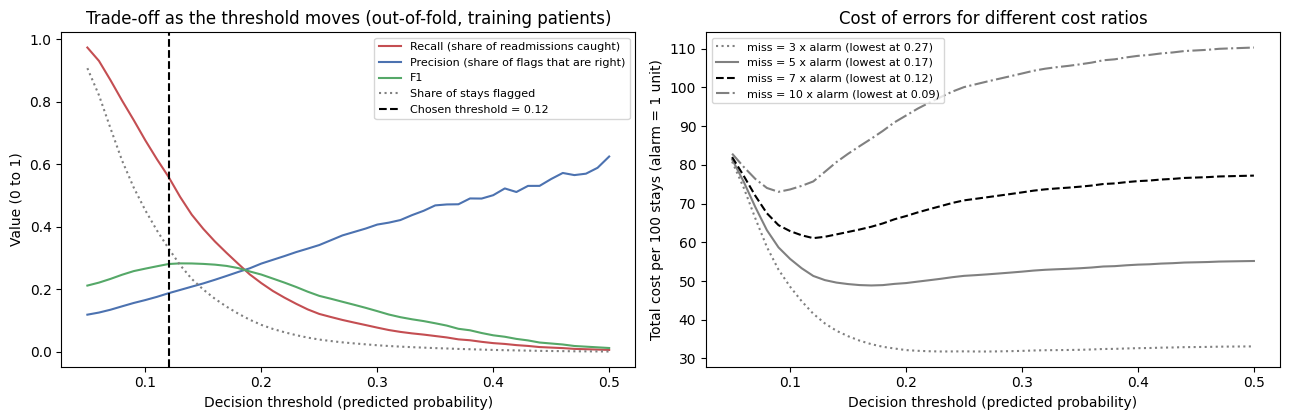

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(thr["Threshold"], thr["Recall"], label="Recall (share of readmissions caught)", color="#C44E52")
axes[0].plot(thr["Threshold"], thr["Precision"], label="Precision (share of flags that are right)", color="#4C72B0")
axes[0].plot(thr["Threshold"], thr["F1"], label="F1", color="#55A868")
axes[0].plot(thr["Threshold"], thr["Flagged (%)"] / 100, label="Share of stays flagged", color="grey", linestyle=":")
axes[0].axvline(THRESHOLD, color="black", linestyle="--", label=f"Chosen threshold = {THRESHOLD:.2f}")
axes[0].set_xlabel("Decision threshold (predicted probability)")
axes[0].set_ylabel("Value (0 to 1)")
axes[0].set_title("Trade-off as the threshold moves (out-of-fold, training patients)")
axes[0].legend(fontsize=8)

for ratio, style in [(3, ":"), (5, "-"), (7, "--"), (10, "-.")]:
    tbl = thr.copy()
    pred_cost = []
    for t in tbl["Threshold"]:
        pred = (oof[FINAL_MODEL] >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_train, pred, labels=[0, 1]).ravel()
        pred_cost.append((ratio * fn + fp) / len(y_train) * 100)
    pred_cost = np.array(pred_cost)
    print(f"Miss = {ratio} x alarm: lowest cost at threshold {tbl['Threshold'][pred_cost.argmin()]:.2f}")
    axes[1].plot(tbl["Threshold"], pred_cost, linestyle=style, color="black" if ratio == COST_MISS else "grey",
                 label=f"miss = {ratio} x alarm (lowest at {tbl['Threshold'][pred_cost.argmin()]:.2f})")
axes[1].set_xlabel("Decision threshold (predicted probability)")
axes[1].set_ylabel("Total cost per 100 stays (alarm = 1 unit)")
axes[1].set_title("Cost of errors for different cost ratios")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/f03_threshold.png", dpi=200, bbox_inches="tight")
plt.show()

**Result.** With a cost ratio of 7, the lowest total cost is at a threshold of **0.12**. At this point the model flags
**33.1%** of stays and catches **56%** of early readmissions, and about **1 in
5** flagged stays is a true early readmission (precision 0.188, against 0.11 if we picked
patients at random).
- The default 0.5 would flag almost nobody (0.1% of stays) and catch under 1% of readmissions.
  With 11% positives, a risk above 50% is rare.
- The highest F1 is at 0.13, so the cost-based choice sits on the flat top of the F1 curve
  (F1 0.281).
- If a miss counted only 5 times an alarm, the best threshold would be 0.17 and only about a third of the
  early readmissions would be caught. At 10 times it would be 0.09, with about half of all stays
  flagged. We chose the middle option because flagging about a third of patients is a workload a discharge team can
  realistically follow up, while still catching more than half of the early returns.

## 8. Final check on the holdout patients

Everything so far used only the training patients. Now we use the holdout test patients **once**: each model,
refitted on all training patients with its chosen setting, predicts the 20% of patients it has never seen, and the
final model is scored at the chosen threshold. These are our patient-grouped validation results.

In [27]:
holdout = {}
prob_test = {}
for name, model in fitted.items():
    prob_test[name] = model.predict_proba(X_test)[:, 1]
    holdout[name] = {"AP": average_precision_score(y_test, prob_test[name]),
                     "AUC": roc_auc_score(y_test, prob_test[name]),
                     "Brier": brier_score_loss(y_test, prob_test[name])}
holdout_table = pd.DataFrame(holdout).T
holdout_table["CV AP (training)"] = [cv_results[m]["AP"] for m in holdout_table.index]
holdout_table.index.name = "Model (holdout test patients)"
holdout_table.to_csv("tables/t13_holdout.csv")
holdout_table

,AP,AUC,Brier,CV AP (training)
Model (holdout test patients),,,,
Logistic regression,0.207,0.669,0.096,0.206
Decision tree,0.209,0.660,0.096,0.201
K-nearest neighbours,0.203,0.648,0.097,0.187
Random forest,0.231,0.676,0.096,0.220
Gradient boosting,0.240,0.681,0.095,0.228


In [28]:
p_final = prob_test[FINAL_MODEL]
pred_final = (p_final >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_final).ravel()
final_metrics = pd.Series({
    "Average precision": average_precision_score(y_test, p_final),
    "ROC-AUC": roc_auc_score(y_test, p_final),
    "Brier score": brier_score_loss(y_test, p_final),
    "Threshold": THRESHOLD,
    "Precision": precision_score(y_test, pred_final),
    "Recall": recall_score(y_test, pred_final),
    "F1": f1_score(y_test, pred_final),
    "Flagged (%)": pred_final.mean() * 100,
})
final_metrics.to_csv("tables/t14_final_holdout_metrics.csv")
cm = pd.DataFrame([[tp, fn], [fp, tn]], index=["Actually readmitted <30", "Not readmitted <30"],
                  columns=["Flagged", "Not flagged"])
cm.to_csv("tables/t15_confusion_matrix.csv")
display(final_metrics.to_frame("Holdout value"))
cm

,Holdout value
Average precision,0.240
ROC-AUC,0.681
Brier score,0.095
Threshold,0.120
Precision,0.189
Recall,0.553
F1,0.282
Flagged (%),33.033


,Flagged,Not flagged
Actually readmitted <30,1014,821
Not readmitted <30,4343,10039


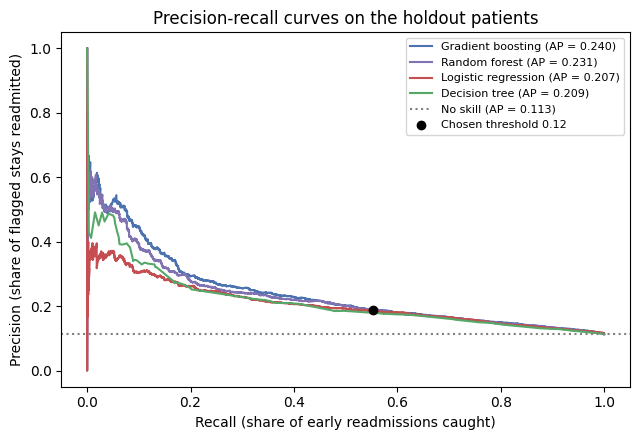

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, colour in [("Gradient boosting", "#4C72B0"), ("Random forest", "#8172B2"),
                     ("Logistic regression", "#C44E52"), ("Decision tree", "#55A868")]:
    prec, rec, _ = precision_recall_curve(y_test, prob_test[name])
    ax.plot(rec, prec, color=colour, label=f"{name} (AP = {holdout[name]['AP']:.3f})")
ax.axhline(y_test.mean(), color="grey", linestyle=":", label=f"No skill (AP = {y_test.mean():.3f})")
ax.scatter([recall_score(y_test, pred_final)], [precision_score(y_test, pred_final)], color="black", zorder=5,
           label=f"Chosen threshold {THRESHOLD:.2f}")
ax.set_xlabel("Recall (share of early readmissions caught)")
ax.set_ylabel("Precision (share of flagged stays readmitted)")
ax.set_title("Precision-recall curves on the holdout patients")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/f04_pr_curves.png", dpi=200, bbox_inches="tight")
plt.show()

**Holdout results (20% of patients, never used before).**
- Gradient boosting reaches **AP 0.240, AUC 0.681 and Brier 0.095**.
  At the threshold of 0.12 it flags 33.0% of stays, with **precision 0.189, recall
  0.553 and F1 0.282**. Of the 1,835 early readmissions it catches 1,014 and misses 821, and it
  flags 4,343 stays that were not readmitted early.
- These numbers are **very close to the cross-validation numbers** (CV AP 0.228, and out-of-fold recall
  0.560 and precision 0.188 at the same threshold). A large drop would have warned us of over-fitting
  or leakage, and there is none. The small gain comes from fitting on all training patients (each CV model saw only 80%
  of them) and from chance in which patients ended up in the holdout.
- The two ensembles stay on top, and gradient boosting stays first. Logistic regression and the decision tree swap places
  (0.207 and 0.209), a difference within the noise. KNN gains the
  most (0.187 → 0.203), because its predictions depend directly on how many stored
  training stays it can compare with.

We expect the hidden held-out result to be in the same range, since our holdout imitates it.

## 9. Performance across patient groups

We check the final model on the holdout patients for each **age band**, **gender** and **race** group. For each group
we report its size, how many early readmissions it has, and how the model does on it.
- **AUC** and **average precision**: how well the model ranks patients inside the group. AP depends on the group's
  own readmission rate, so it is compared with that rate.
- **Recall** (at our threshold): the share of the group's early readmissions that the model catches. A low recall
  means the group's high-risk patients are more often **missed**.
- **False alarm rate**: the share of the group's non-readmitted patients who are flagged anyway.
- **Mean predicted vs observed rate**: whether the probabilities are too high or too low for that group.

In [30]:
test_raw = raw.iloc[test_idx].reset_index(drop=True)
age_band = pd.cut(test_raw["age"].str.extract(r"(\d+)")[0].astype(int), bins=[0, 40, 60, 80, 100], right=False,
                  labels=["Under 40", "40-59", "60-79", "80 and over"])

def group_metrics(labels, title):
    rows = []
    for level in pd.Series(labels).dropna().unique():
        m = (pd.Series(labels) == level).to_numpy()
        yt, pt, pr = y_test[m], p_final[m], pred_final[m]
        has_both = 0 < yt.sum() < len(yt)
        rows.append({"Variable": title, "Group": level, "Stays": m.sum(), "Readmitted <30": int(yt.sum()),
                     "Rate (%)": yt.mean() * 100,
                     "Mean predicted (%)": pt.mean() * 100,
                     "AUC": roc_auc_score(yt, pt) if has_both else np.nan,
                     "AP": average_precision_score(yt, pt) if has_both else np.nan,
                     "Recall": pr[yt == 1].mean() if yt.sum() else np.nan,
                     "False alarm rate": pr[yt == 0].mean(),
                     "Precision": yt[pr == 1].mean() if pr.sum() else np.nan})
    return pd.DataFrame(rows).sort_values("Stays", ascending=False)

fairness = pd.concat([group_metrics(age_band.astype(str), "Age"),
                      group_metrics(test_raw["gender"], "Gender"),
                      group_metrics(test_raw["race"].replace("?", "Unknown"), "Race")], ignore_index=True)
overall = group_metrics(np.array(["All"] * len(y_test)), "All")
fairness = pd.concat([overall, fairness], ignore_index=True)
fairness.to_csv("tables/t16_subgroups.csv", index=False)
fairness

,Variable,Group,Stays,Readmitted <30,Rate (%),Mean predicted (%),AUC,AP,Recall,False alarm rate,Precision
0,All,All,16217,1835,11.315,11.070,0.681,0.240,0.553,0.302,0.189
1,Age,60-79,7728,888,11.491,11.302,0.661,0.219,0.535,0.315,0.181
2,Age,40-59,4409,476,10.796,10.328,0.719,0.283,0.553,0.227,0.227
3,Age,80 and over,3107,374,12.037,11.904,0.647,0.229,0.591,0.404,0.167
4,Age,Under 40,973,97,9.969,9.919,0.715,0.279,0.567,0.218,0.224
5,Gender,Female,8620,999,11.589,11.222,0.675,0.239,0.568,0.319,0.189
6,Gender,Male,7597,836,11.004,10.897,0.687,0.240,0.535,0.283,0.190
7,Race,Caucasian,12167,1361,11.186,11.142,0.681,0.239,0.558,0.308,0.186
8,Race,AfricanAmerican,3001,367,12.229,11.273,0.669,0.240,0.548,0.314,0.196
9,Race,Unknown,374,31,8.289,8.616,0.669,0.231,0.452,0.181,0.184


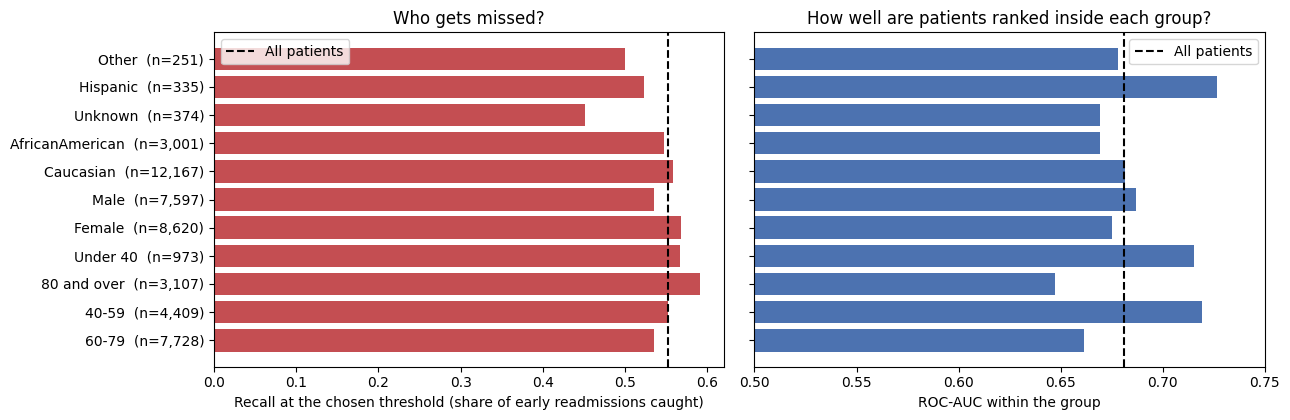

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
plot_df = fairness[(fairness["Stays"] >= 100) & (fairness["Variable"] != "All")].copy()
plot_df["Label"] = plot_df["Group"] + "  (n=" + plot_df["Stays"].map("{:,}".format) + ")"
yy = np.arange(len(plot_df))
axes[0].barh(yy, plot_df["Recall"], color="#C44E52")
axes[0].axvline(fairness.loc[fairness["Group"] == "All", "Recall"].item(), color="black", linestyle="--", label="All patients")
axes[0].set_yticks(yy, plot_df["Label"])
axes[0].set_xlabel("Recall at the chosen threshold (share of early readmissions caught)")
axes[0].set_title("Who gets missed?")
axes[0].legend()
axes[1].barh(yy, plot_df["AUC"], color="#4C72B0")
axes[1].axvline(fairness.loc[fairness["Group"] == "All", "AUC"].item(), color="black", linestyle="--", label="All patients")
axes[1].set_yticks(yy, [""] * len(yy))
axes[1].set_xlim(0.5, 0.75)
axes[1].set_xlabel("ROC-AUC within the group")
axes[1].set_title("How well are patients ranked inside each group?")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/f05_subgroups.png", dpi=200, bbox_inches="tight")
plt.show()

**Findings (holdout patients).**
- **Gender.** The model works about equally well for women and men (AUC 0.675 and 0.687, AP
  0.239 and 0.240). Women's early readmissions are caught a little more often (recall 0.57 vs
  0.53), with slightly more false alarms (0.32 vs 0.28).
- **Age** shows the clearest difference. The model ranks patients best aged 40 to 59 (AUC 0.719) and under 40
  (0.715) and worst at 80 and over (0.647) and 60 to 79 (0.661). Patients aged 80 and over get
  the **most false alarms** (40% of their other stays are flagged, against 22%
  under 40), because almost everyone that age has a raised predicted risk, and patients aged 60 to 79 have the **lowest
  recall** (0.53). For older patients, risk seems to depend more on things the data do not record, such as
  frailty or support at home.
- **Race.** Caucasian and African American patients, the two large groups, have similar AUC (0.681 and
  0.669) and recall (0.56 and 0.55). But the model **under-estimates risk for African
  American patients** (mean prediction 11.3% against 12.2% observed) and for
  **Hispanic patients** (10.3% against 13.1%, though from only
  44 readmissions). The Asian (89 stays, 6 readmissions), Other and
  Unknown groups are too small to judge. For the Asian group, one patient more or less changes recall by
  17 points. The Unknown-race group has a low recall (0.45), but it rests on only
  31 readmissions.

**Which groups have higher error rates?** Older patients (weaker ranking, many false alarms for those 80 and over, the
lowest recall for those 60 to 79) and African American and Hispanic patients, whose risk is under-estimated. The gaps
are modest next to the overall limits of the model (AUC 0.681 for everyone), but they mean one threshold
does not serve every group equally. We did not set separate thresholds per group, since race-based rules raise their own
fairness problems and several groups are too small to tune on. A hospital using the model should keep checking recall by
group.

In [32]:
# Did leaving race out of the inputs help or hurt the race groups? Refit the chosen setting
# with race added back (training patients only) and compare on the holdout patients.
race_test = test_raw["race"].replace("?", "Unknown")
X_train_r = X_train.assign(race=train_raw["race"].replace("?", "Unknown").to_numpy())
X_test_r = X_test.assign(race=race_test.to_numpy())
with_race = Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES + ["race"])),
                      ("clf", clone(gb_setting))]).fit(X_train_r, y_train)
p_race = with_race.predict_proba(X_test_r)[:, 1]
print(f"Holdout AP without race {average_precision_score(y_test, p_final):.4f} | with race {average_precision_score(y_test, p_race):.4f}")

rows = []
for g in ["Caucasian", "AfricanAmerican", "Hispanic"]:
    m = (race_test == g).to_numpy()
    for label, pp in [("Without race (submitted)", p_final), ("With race", p_race)]:
        rows.append({"Group": g, "Model": label, "Stays": m.sum(),
                     "Observed rate (%)": y_test[m].mean() * 100, "Mean predicted (%)": pp[m].mean() * 100,
                     "Recall": ((pp[m] >= THRESHOLD) & (y_test[m] == 1)).sum() / y_test[m].sum()})
race_check = pd.DataFrame(rows).set_index(["Group", "Model"])
race_check.to_csv("tables/t17_race_input_check.csv")
race_check.round(3)

Holdout AP without race 0.2398 | with race 0.2413


Stays  Observed rate (%)  Mean predicted (%)  Recall
Group           Model                                                                         
Caucasian       Without race (submitted)  12167             11.186              11.142   0.558
                With race                 12167             11.186              11.189   0.559
AfricanAmerican Without race (submitted)   3001             12.229              11.273   0.548
                With race                  3001             12.229              11.125   0.556
Hispanic        Without race (submitted)    335             13.134              10.257   0.523
                With race                   335             13.134              10.101   0.523

**Did leaving race out help or hurt?** It makes almost no difference either way. Overall holdout AP is
0.240 without race and 0.241 with it. For African American patients recall is
0.548 without race and 0.556 with it (a difference of about
3 patients), and the mean prediction stays below the observed
rate either way (11.3% and 11.1% against 12.2%). For
Hispanic patients recall is 0.523 without and 0.523 with race. Adding race would therefore not fix
the under-estimation and would not make the model clearly more accurate, so leaving it out costs nothing measurable,
and the decision about who gets follow-up does not depend on a social category. Leaving race out does not guarantee
fairness either, because other inputs (payer code, for example) can partly stand in for it, which is why we check the
results by group.

## 10. Final model for submission

The final pipeline is the chosen model with its chosen setting, **refitted on all 81,281 development stays**
(training and holdout patients together), because more patients give a better model and the settings and threshold
are already fixed. The threshold stays the one chosen on the training patients.

In [33]:
final_pipeline = clone(fitted[FINAL_MODEL]).fit(X, y)
Path("model").mkdir(exist_ok=True)
joblib.dump(final_pipeline, "model/pipeline.joblib")
with open("threshold.json", "w") as f:
    json.dump({"threshold": round(THRESHOLD, 2)}, f)
print("Saved model/pipeline.joblib and threshold.json =", round(THRESHOLD, 2))
print(final_pipeline)

Saved model/pipeline.joblib and threshold.json = 0.12
Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age_years',
                                                   'time_in_hospital',
                                                   'num_lab_procedures',
                                                   'num_procedures',
                                                   'num_medications',
                                                   'number_diagnoses',
                                                   'log_number_outpatient',
                           

### Self-check of the prediction script
We run `predict.py` the way the instructor will, on a 500-row sample without the target, and then on a deliberately
messy copy (unseen codes, `"?"` in numeric columns, a missing column, a blank row) to make sure it never crashes and
always returns one valid probability per row, in order.

In [34]:
import importlib
importlib.reload(predict)   # loads the model file we just saved

sample = raw.sample(500, random_state=SEED).drop(columns=["readmitted"])
p_sample = predict.predict_proba(sample)

messy = sample.copy().astype(object)
messy.iloc[:5, messy.columns.get_loc("diag_1")] = "999.9X"           # diagnosis code never seen
messy.iloc[:5, messy.columns.get_loc("admission_type_id")] = 99      # ID code not in IDS_mapping
messy.iloc[:5, messy.columns.get_loc("payer_code")] = "ZZ"           # unseen payer
messy.iloc[5:10, messy.columns.get_loc("num_medications")] = "?"     # "?" in a numeric column
messy.iloc[10, :] = np.nan                                           # completely blank row
messy = messy.drop(columns=["medical_specialty"])                     # a whole column missing
p_messy = predict.predict_proba(messy)

for label, p_ in [("sample", p_sample), ("messy", p_messy)]:
    assert p_.shape == (500,) and np.isfinite(p_).all() and (p_ >= 0).all() and (p_ <= 1).all()
    print(f"{label}: 500 probabilities, min {p_.min():.3f}, max {p_.max():.3f}, no NaN")
print("Saved model reproduces itself:", np.allclose(p_sample, final_pipeline.predict_proba(clean(sample))[:, 1]))

sample: 500 probabilities, min 0.001, max 0.590, no NaN
messy: 500 probabilities, min 0.001, max 0.590, no NaN
Saved model reproduces itself: True


## Summary
- **Target.** Readmission within 30 days, 11.1% of stays, judged by average precision, ROC-AUC and the Brier score.
- **Cleaning.** One function, `clean()` in `predict.py`, shared by the notebook and the prediction script. Missing values
  become "Unknown" or "Not tested", codes are grouped by meaning (ICD-9 chapters, IDS_mapping.csv), skewed counts are
  logged, and race is not an input.
- **Validation.** Split by patient, a 20% holdout plus grouped 5-fold cross-validation on the rest.
- **Model.** Gradient boosting, CV AP 0.228, holdout AP 0.240, AUC 0.681,
  Brier 0.095.
- **Threshold.** 0.12 (miss = 7 × unneeded follow-up). On the holdout it gives precision 0.189, recall
  0.553 and F1 0.282.
- **Fairness.** Similar for women and men, weaker for older patients, and risk is under-estimated for African American
  and Hispanic patients.